Load and clean dataset


In [ ]:
import pandas as pd
import numpy as np
df=pd.read_csv('Kevin_Hillstrom_E-MailAnalytics.csv')
print(df)
df['treatment']=df['segment'].map({'Womens E-Mail':1,'Mens E-Mail':1,'No E-Mail':0})
feature_cols=['recency','history_segment','history','mens','zip_code','womens','newbie','channel']
df_features=pd.get_dummies(df[feature_cols],drop_first=True)
df_features


       recency history_segment  history  mens  womens   zip_code  newbie  \
0           10  2) $100 - $200   142.44     1       0  Surburban       0   
1            6  3) $200 - $350   329.08     1       1      Rural       1   
2            7  2) $100 - $200   180.65     0       1  Surburban       1   
3            9  5) $500 - $750   675.83     1       0      Rural       1   
4            2    1) $0 - $100    45.34     1       0      Urban       0   
...        ...             ...      ...   ...     ...        ...     ...   
63995       10  2) $100 - $200   105.54     1       0      Urban       0   
63996        5    1) $0 - $100    38.91     0       1      Urban       1   
63997        6    1) $0 - $100    29.99     1       0      Urban       1   
63998        1  5) $500 - $750   552.94     1       0  Surburban       1   
63999        1  4) $350 - $500   472.82     0       1  Surburban       0   

            channel        segment  visit  conversion  spend  
0             Phone  Wom

,recency,history,mens,womens,newbie,history_segment_2) $100 - $200,history_segment_3) $200 - $350,history_segment_4) $350 - $500,history_segment_5) $500 - $750,"history_segment_6) $750 - $1,000","history_segment_7) $1,000 +",zip_code_Surburban,zip_code_Urban,channel_Phone,channel_Web
0,10,142.44,1,0,0,True,False,False,False,False,False,True,False,True,False
1,6,329.08,1,1,1,False,True,False,False,False,False,False,False,False,True
2,7,180.65,0,1,1,True,False,False,False,False,False,True,False,False,True
3,9,675.83,1,0,1,False,False,False,True,False,False,False,False,False,True
4,2,45.34,1,0,0,False,False,False,False,False,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63995,10,105.54,1,0,0,True,False,False,False,False,False,False,True,False,True
63996,5,38.91,0,1,1,False,False,False,False,False,False,False,True,True,False
63997,6,29.99,1,0,1,False,False,False,False,False,False,False,True,True,False
63998,1,552.94,1,0,1,False,False,False,True,False,False,True,False,False,False


Separate features,treatment and outcome arrays

In [ ]:
X_data=df_features.values
treatment_data=df['treatment'].values
y_data=df['conversion'].values
X_data
treatment_data
y_data

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
!pip install econml lightgbm pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 13.0 MB/s eta 0:00:00


train the X-Learners Meta-Learners


In [ ]:
from econml.metalearners import XLearner
from lightgbm import LGBMRegressor,LGBMClassifier
xl=XLearner(models=LGBMRegressor(random_state=42),
            propensity_model=LGBMClassifier(random_state=42))
xl.fit(Y=y_data,T=treatment_data,X=X_data)
uplift_scores=xl.effect(X_data).flatten()
df['uplift_score']=uplift_scores

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007343 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 294
[LightGBM] [Info] Number of data points in the train set: 21306, number of used features: 15
[LightGBM] [Info] Start training from score 0.005726
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011677 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 294
[LightGBM] [Info] Number of data points in the train set: 42694, number of used features: 15
[LightGBM] [Info] Start training from score 0.010681


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003121 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 294
[LightGBM] [Info] Number of data points in the train set: 21306, number of used features: 15
[LightGBM] [Info] Start training from score 0.004838
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006512 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 294
[LightGBM] [Info] Number of data points in the train set: 42694, number of used features: 15
[LightGBM] [Info] Start training from score 0.004840
[LightGBM] [Info] Number of positive: 42694, number of negative: 21306
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009957 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 294
[LightGBM] [Info] Number of data points in the train

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Evaluate with a Qini Curve & AUUC Score

In [ ]:
eval_df=pd.DataFrame({
    'conversion':y_data,
    'treatment':treatment_data,
    'uplift_score':uplift_scores
}).sort_values(by='uplift_score',ascending=False).reset_index(drop=True)

eval_df['t_count']=eval_df['treatment'].cumsum()
eval_df['c_count']=(1-eval_df['treatment']).cumsum()
total_c=(1-eval_df['treatment']).sum()

eval_df['t_gain'] = (eval_df['conversion'] * eval_df['treatment']).cumsum()
eval_df['c_gain'] = (eval_df['conversion'] * (1 - eval_df['treatment'])).cumsum()
eval_df['cumulative_uplift'] = eval_df['t_gain'] - (eval_df['t_count'] / total_c) * eval_df['c_gain']

total_area = eval_df['cumulative_uplift'].sum()
random_line = np.linspace(0, eval_df['cumulative_uplift'].iloc[-1], len(eval_df))
auuc_score = (total_area - random_line.sum()) / random_line.sum()

Run the Business Financial Simulation

Net Profit Gain: $51,525.00


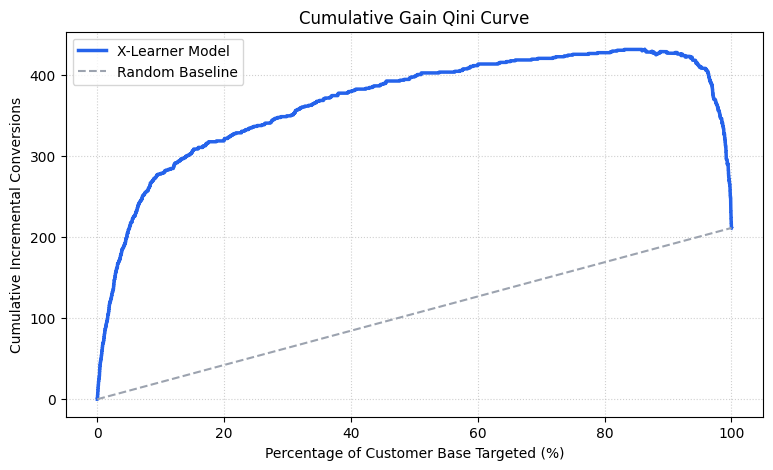

In [ ]:
def simulate_campaign_financials(eval_df, budget_pct=0.20):
    profit_per_conversion = 45.0
    cost_per_message = 1.50

    n_total = len(eval_df)
    n_target = int(n_total * budget_pct)

    uplift_cohort = eval_df.head(n_target)
    uplift_conversions = uplift_cohort[uplift_cohort['treatment'] == 1]['conversion'].sum() * (n_total / n_target)
    uplift_net_profit = (uplift_conversions * profit_per_conversion) - (n_target * cost_per_message)

    random_cohort = eval_df.sample(n=n_target, random_state=42)
    random_conversions = random_cohort[random_cohort['treatment'] == 1]['conversion'].sum() * (n_total / n_target)
    random_net_profit = (random_conversions * profit_per_conversion) - (n_target * cost_per_message)

    print(f"Net Profit Gain: ${(uplift_net_profit - random_net_profit):,.2f}")
    import matplotlib.pyplot as plt
    plt.figure(figsize=(9, 5))
    plt.plot(np.linspace(0, 100, len(eval_df)), eval_df['cumulative_uplift'], label='X-Learner Model', color='#2563eb', lw=2.5)
    plt.plot([0, 100], [0, eval_df['cumulative_uplift'].iloc[-1]], label='Random Baseline', linestyle='--', color='#9ca3af', lw=1.5)
    plt.xlabel('Percentage of Customer Base Targeted (%)')
    plt.ylabel('Cumulative Incremental Conversions')
    plt.title('Cumulative Gain Qini Curve')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6 )

    plt.show()
simulate_campaign_financials(eval_df, budget_pct=0.20)